# Test 3 — Wall interactions and fragmentation

**Scientific question.** Are seeds 0 and 2 already disconnected initially, do new persistent splits follow boundary encounters, and does moving the same initial school farther from the walls change the outcome? Seed 1 is the comparison run; its control status is assessed from its actual trajectory rather than assumed.

**Why this is needed.** The whole-group centroid can remain central while individual fish touch opposite walls. We therefore examine centroid-to-wall distance, mean and minimum fish-to-wall distances, and the count of fish whose recorded move reflects. Connectivity is an observational graph with edges at distance ≤ 5.5 BL; it does not steer the fish.

**Hypotheses.** (H1) Some persistent splits follow boundary encounters and change when the same initial configuration is translated into a larger arena. (H2) splits can also arise through finite-range local interactions away from immediate wall contacts. The two explanations can coexist. Temporal proximity alone does not establish that reflection caused a split.

The model and observer-only DataCollector remain shared with the preceding checks. No wall force, light field, speed modulation or cohesion controller is added. Local interaction rules are motivated by [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065); this is an implementation/boundary diagnostic, not an additional biological claim.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"
PAPERS_DIR = MODEL_DIR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from handlings.trial_one.diagnostics import (
    run_case, graph_components, fragmentation_episodes, summarize_case,
)

OUTPUT_DIR = PAPERS_DIR / "handlings" / "trial_one"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Baseline: diagnose persistent connected-to-fragmented transitions

Seeds 0, 2 and 1 are run for 62.5 s in the unchanged 20 × 20 BL arena, with 20 fish, speed 1 BL/s and `dt=0.125 s`. A persistent episode lasts at least **2.5 s** of consecutive fragmented post-update intervals. This is a diagnostic convention, not a biological constant.

We distinguish fragmentation already present at initialization from a split that follows a connected state. `StartTime` is the first observed fragmented sample: the transition itself lies in its preceding update interval. Right-censored episodes may continue after the observation window.

In [2]:
SEEDS = [0, 2, 1]
DURATION = 62.5
PERSISTENCE_S = 2.5
WINDOW_S = 3.0
baseline_cases = {}
case_rows = []
event_rows = []
all_wall_frames = []
for seed in SEEDS:
    model, frame, agents = run_case(seed=seed, duration=DURATION)
    baseline_cases[seed] = (model, frame, agents)
    summary = summarize_case(frame, persistence_s=PERSISTENCE_S)
    summary.update({"Seed": seed, "Arena": "20 x 20", "Width": 20,
                    "InitialGroups": int(frame.iloc[0]["NumberOfGroups"]),
                    "InitialComponentSizes": frame.iloc[0]["ComponentSizes"],
                    "ReflectedFishStepsPerSecond": frame["ReflectedFishCount"].sum() / DURATION,
                    "MeanMinimumFishWallDistance": frame.iloc[1:]["MinimumFishDistanceToWall"].mean()})
    case_rows.append(summary)
    all_wall_frames.append(frame.assign(Seed=seed, Arena="20 x 20", Step=frame.index))
    episodes = fragmentation_episodes(frame, min_duration_s=PERSISTENCE_S)
    selected_events = episodes.loc[episodes["Persistent"].astype(bool) & episodes["FromConnected"].astype(bool)]
    for _, event in selected_events.iterrows():
        step = int(event["StartStep"])
        onset = frame.loc[step]
        before = frame.loc[(frame["Time"] >= event["StartTime"] - WINDOW_S) & (frame["Time"] < event["StartTime"])]
        event_rows.append({
            "Seed": seed, **event.to_dict(),
            "CentroidWallDistanceAtOnset": onset["DistanceCentroidToNearestWall"],
            "MinimumFishWallDistanceAtOnset": onset["MinimumFishDistanceToWall"],
            "MeanFishWallDistanceAtOnset": onset["MeanFishDistanceToNearestWall"],
            "ReflectedFishStepsInPrevious3s": int(before["ReflectedFishCount"].sum()),
            "MinimumFishWallDistanceInPrevious3s": before["MinimumFishDistanceToWall"].min(),
            "OnsetLargestGroupFraction": onset["LargestGroupFraction"],
            "OnsetPolarization": onset["Polarization"],
            "OnsetMeanNND": onset["MeanNND"],
            "OnsetGroupSpread": onset["MeanDistanceToCentroid"],
        })
event_columns = ["Seed", "StartStep", "EndStep", "StartTime", "EndTime", "Duration_s", "FromConnected",
                 "RightCensored", "Persistent", "SizesAtStart", "Reconnected", "CentroidWallDistanceAtOnset",
                 "MinimumFishWallDistanceAtOnset", "MeanFishWallDistanceAtOnset", "ReflectedFishStepsInPrevious3s",
                 "MinimumFishWallDistanceInPrevious3s", "OnsetLargestGroupFraction", "OnsetPolarization",
                 "OnsetMeanNND", "OnsetGroupSpread"]
wall_event_table = pd.DataFrame(event_rows, columns=event_columns)
wall_baseline_summary = pd.DataFrame(case_rows)
wall_baseline_summary[["Seed", "InitialComponentSizes", "ConnectedTimeFraction", "PersistentSplitEvents",
                       "PersistentFragmentedTimeFraction", "FinalComponentSizes",
                       "ReflectedFishStepsPerSecond", "MeanMinimumFishWallDistance"]].round(4)

,Seed,InitialComponentSizes,ConnectedTimeFraction,PersistentSplitEvents,PersistentFragmentedTimeFraction,FinalComponentSizes,ReflectedFishStepsPerSecond,MeanMinimumFishWallDistance
0,0,18+2,0.0,0,1.0,10+10,9.680,0.1483
1,2,19+1,0.0,0,1.0,19+1,2.112,1.3533
2,1,20,1.0,0,0.0,20,1.408,1.6423


In [3]:
if len(wall_event_table):
    display(wall_event_table[["Seed", "StartTime", "Duration_s", "SizesAtStart",
                              "RightCensored", "CentroidWallDistanceAtOnset",
                              "MinimumFishWallDistanceAtOnset", "ReflectedFishStepsInPrevious3s",
                              "OnsetLargestGroupFraction", "OnsetGroupSpread"]].round(4))
else:
    display(Markdown("No persistent split from a connected state was observed in this window."))
wall_event_table.to_csv(DATA_DIR / "03_wall_events.csv", index=False)

No persistent split from a connected state was observed in this window.

## Inspect initial disconnection without inventing a later split onset

An observed split from one connected graph and fragmentation already present at t=0 are different results. If a seed has a persistent connected-to-fragmented event, we show ±3 s around its first event. If its graph is already disconnected at t=0, we instead show the first 3 s and label that window explicitly: no pre-initialization observations exist. A connected comparison seed is shown around the same physical anchor.

The distance panel shows all three wall-distance measures. The bottom panel counts reflected fish per update; it is not a collision count. Recent reflections would establish temporal proximity, not causation. Initial disconnection necessarily precedes any simulated reflection.

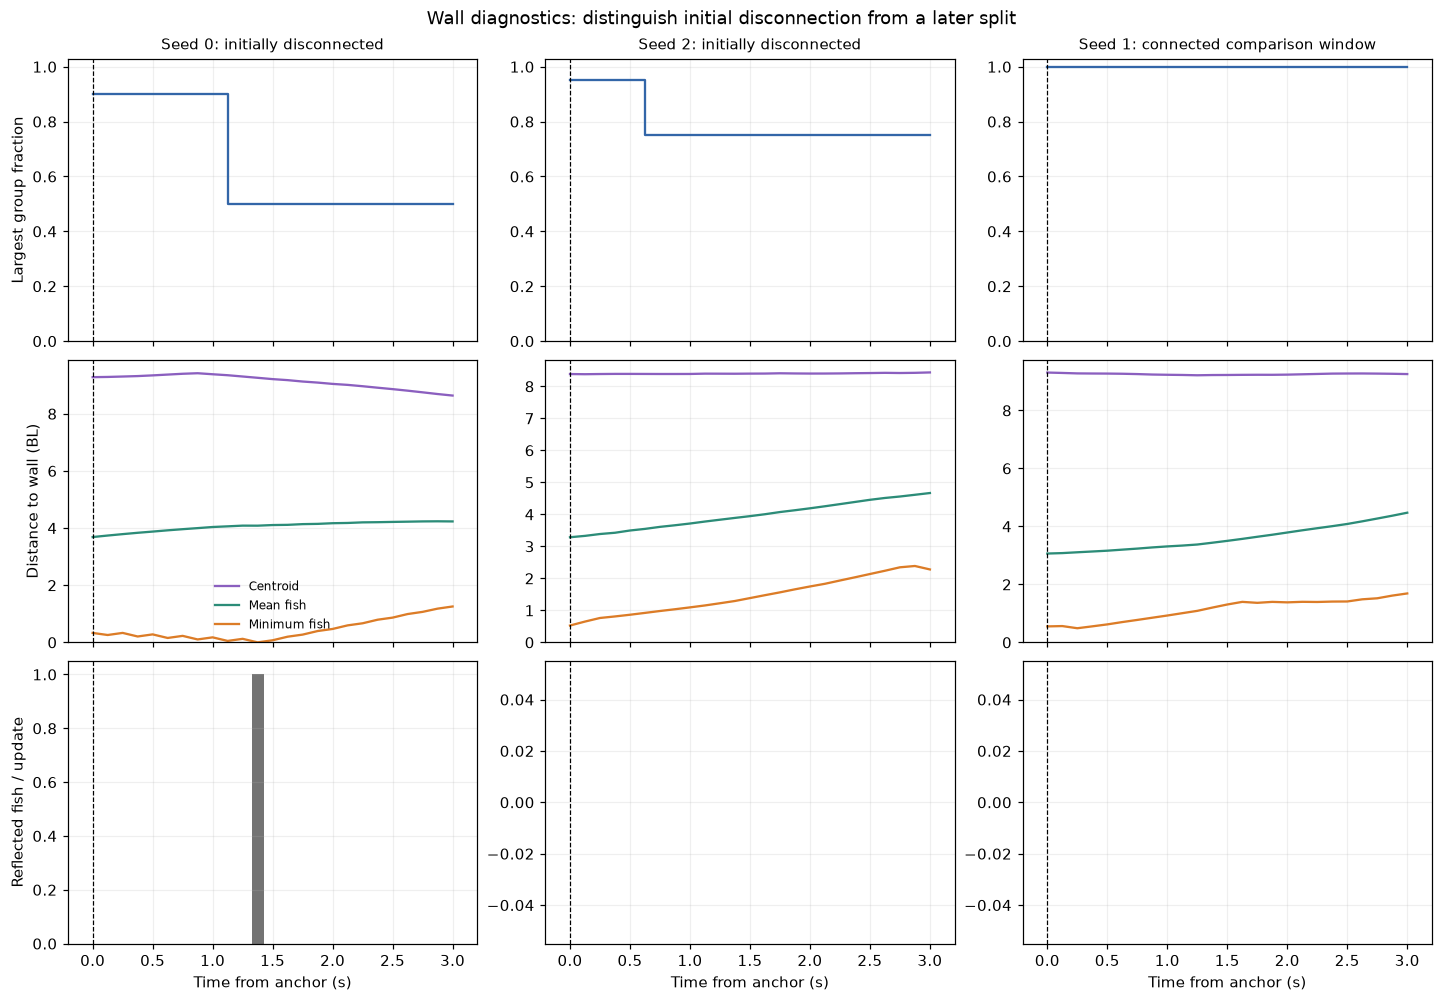

In [4]:
if len(wall_event_table) and wall_event_table["Seed"].eq(0).any():
    control_anchor = wall_event_table.loc[wall_event_table["Seed"].eq(0), "StartTime"].iloc[0]
else:
    control_anchor = 0.0

window_frames = []
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex="col", constrained_layout=True)
for column, seed in enumerate(SEEDS):
    _, frame, _ = baseline_cases[seed]
    events = wall_event_table.loc[wall_event_table["Seed"].eq(seed)]
    has_own_event = len(events) > 0
    initially_disconnected = frame.iloc[0]["NumberOfGroups"] > 1
    if has_own_event:
        anchor, kind = float(events["StartTime"].iloc[0]), "observed split"
    elif initially_disconnected:
        anchor, kind = 0.0, "initially disconnected"
    else:
        anchor, kind = float(control_anchor), "connected comparison window"
    window = frame.loc[frame["Time"].between(max(0, anchor-WINDOW_S), min(DURATION, anchor+WINDOW_S))].copy()
    window["RelativeTime"] = window["Time"] - anchor
    window_frames.append(window.assign(Seed=seed, AnchorTime=anchor, AnchorKind=kind))
    x = window["RelativeTime"]
    axes[0, column].step(x, window["LargestGroupFraction"], where="post", color="#3366a8")
    axes[0, column].set_ylim(0, 1.03)
    axes[0, column].set_title(f"Seed {seed}: {kind}", fontsize=10)
    for metric, label, color in [
        ("DistanceCentroidToNearestWall", "Centroid", "#8b5fbf"),
        ("MeanFishDistanceToNearestWall", "Mean fish", "#2c8c78"),
        ("MinimumFishDistanceToWall", "Minimum fish", "#dc7c27"),
    ]:
        axes[1, column].plot(x, window[metric], label=label, color=color)
    axes[1, column].set_ylim(bottom=0)
    axes[2, column].bar(x, window["ReflectedFishCount"], width=0.10, color="0.45")
    axes[2, column].set_xlabel("Time from anchor (s)")
    for row in range(3):
        axes[row, column].axvline(0, color="black", linestyle="--", linewidth=0.8)
        axes[row, column].grid(alpha=0.2)
axes[0, 0].set_ylabel("Largest group fraction")
axes[1, 0].set_ylabel("Distance to wall (BL)")
axes[2, 0].set_ylabel("Reflected fish / update")
axes[1, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Wall diagnostics: distinguish initial disconnection from a later split")
fig.savefig(FIGURE_DIR / "03_wall_event_windows.png", dpi=180)
plt.show()
pd.concat(window_frames).to_csv(DATA_DIR / "03_wall_event_windows.csv", index=False)

## Matched initial geometry in a larger arena

The intervention uses a 40 × 40 BL arena and translates every original position by `(10, 10)`, keeping headings, pair distances, initial local density, interaction graph, fish IDs, speed, timestep, radii and simulated duration unchanged. It moves the school farther from all four walls without rescaling its geometry.

The available arena area and nominal density N/area still change. Longer-term encounter opportunities and available travel distance can therefore differ. This is a controlled wall/arena intervention, not a complete isolation of every boundary-versus-density effect. We preserve the reflection rule.

As an implementation control, translated trajectories should agree up to the first baseline wall reflection, within rounding tolerance. Changes after that point support boundary sensitivity, but do not prove that all fragmentation is a wall artefact.

In [5]:
expanded_cases = {}
prewall_checks = []
for seed in SEEDS:
    baseline_model, baseline_frame, baseline_agents = baseline_cases[seed]
    initial = baseline_agents.xs(0, level="Step")
    positions = initial[["X", "Y"]].to_numpy()
    headings = initial[["DirX", "DirY"]].to_numpy()
    expanded_model, expanded_frame, expanded_agents = run_case(
        seed=seed, duration=DURATION, width=40, height=40,
        initial_state=(positions + 10, headings),
    )
    expanded_cases[seed] = (expanded_model, expanded_frame, expanded_agents)
    np.testing.assert_allclose(expanded_agents.xs(0)[["X", "Y"]], positions + 10)
    np.testing.assert_allclose(expanded_agents.xs(0)[["DirX", "DirY"]], headings)
    np.testing.assert_allclose(
        np.linalg.norm(positions[:, None]-positions[None, :], axis=2),
        np.linalg.norm((positions+10)[:, None]-(positions+10)[None, :], axis=2), atol=1e-12,
    )
    first_reflections = baseline_frame.index[baseline_frame["ReflectedFishCount"].gt(0)]
    first_reflection = int(first_reflections[0]) if len(first_reflections) else len(baseline_frame)
    steps_to_compare = list(range(first_reflection))
    before_small = baseline_agents.loc[(steps_to_compare, slice(None)), :]
    before_large = expanded_agents.loc[(steps_to_compare, slice(None)), :]
    np.testing.assert_allclose(before_large[["X", "Y"]].to_numpy()-10,
                               before_small[["X", "Y"]].to_numpy(), atol=1e-10, rtol=0)
    np.testing.assert_allclose(before_large[["DirX", "DirY"]], before_small[["DirX", "DirY"]], atol=1e-10, rtol=0)
    prewall_checks.append({"Seed": seed, "CheckedStatesBeforeFirstReflection": first_reflection,
                           "FirstBaselineReflectionTime_s": first_reflection*baseline_model.dt,
                           "TranslationCheck": "passed"})
    summary = summarize_case(expanded_frame, persistence_s=PERSISTENCE_S)
    summary.update({"Seed": seed, "Arena": "40 x 40 translated", "Width": 40,
                    "InitialGroups": int(expanded_frame.iloc[0]["NumberOfGroups"]),
                    "InitialComponentSizes": expanded_frame.iloc[0]["ComponentSizes"],
                    "ReflectedFishStepsPerSecond": expanded_frame["ReflectedFishCount"].sum()/DURATION,
                    "MeanMinimumFishWallDistance": expanded_frame.iloc[1:]["MinimumFishDistanceToWall"].mean()})
    case_rows.append(summary)
    all_wall_frames.append(expanded_frame.assign(Seed=seed, Arena="40 x 40 translated", Step=expanded_frame.index))
wall_case_summary = pd.DataFrame(case_rows)
wall_case_summary.to_csv(DATA_DIR / "03_wall_case_summary.csv", index=False)
pd.concat(all_wall_frames).to_csv(DATA_DIR / "03_wall_frames.csv", index=False)
display(pd.DataFrame(prewall_checks))
wall_case_summary[["Seed", "Arena", "ConnectedTimeFraction", "PersistentSplitEvents",
                   "PersistentFragmentedTimeFraction", "FinalComponentSizes",
                   "ReflectedFishStepsPerSecond"]].round(4)

,Seed,CheckedStatesBeforeFirstReflection,FirstBaselineReflectionTime_s,TranslationCheck
0,0,11,1.375,passed
1,2,46,5.750,passed
2,1,142,17.750,passed


,Seed,Arena,ConnectedTimeFraction,PersistentSplitEvents,PersistentFragmentedTimeFraction,FinalComponentSizes,ReflectedFishStepsPerSecond
0,0,20 x 20,0.0,0,1.0,10+10,9.680
1,2,20 x 20,0.0,0,1.0,19+1,2.112
2,1,20 x 20,1.0,0,0.0,20,1.408
3,0,40 x 40 translated,0.0,0,1.0,10+10,3.648
4,2,40 x 40 translated,0.0,0,1.0,15+5,0.784
5,1,40 x 40 translated,1.0,0,0.0,20,0.784


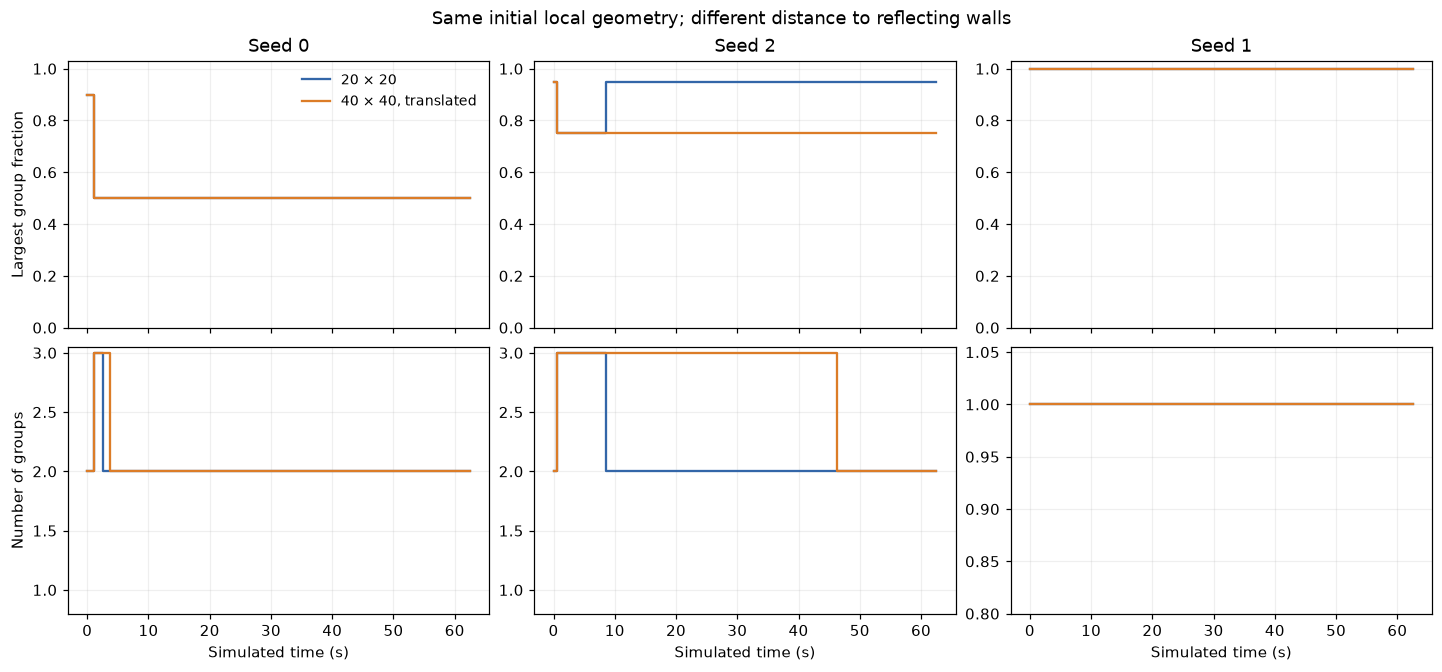

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, constrained_layout=True)
for column, seed in enumerate(SEEDS):
    for label, cases, color in [("20 × 20", baseline_cases, "#3366a8"),
                                ("40 × 40, translated", expanded_cases, "#dc7c27")]:
        _, frame, _ = cases[seed]
        axes[0, column].step(frame["Time"], frame["LargestGroupFraction"], where="post", label=label, color=color)
        axes[1, column].step(frame["Time"], frame["NumberOfGroups"], where="post", color=color)
    axes[0, column].set_title(f"Seed {seed}")
    axes[0, column].set_ylim(0, 1.03)
    axes[1, column].set_xlabel("Simulated time (s)")
    axes[1, column].set_ylim(bottom=0.8)
    for row in range(2):
        axes[row, column].grid(alpha=0.2)
axes[0, 0].set_ylabel("Largest group fraction")
axes[1, 0].set_ylabel("Number of groups")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("Same initial local geometry; different distance to reflecting walls")
fig.savefig(FIGURE_DIR / "03_matched_arena_connectivity.png", dpi=180)
plt.show()

In [7]:
wall_wide = wall_case_summary.pivot(index="Seed", columns="Arena", values="ConnectedTimeFraction")
wall_wide["Expanded minus baseline"] = wall_wide["40 x 40 translated"] - wall_wide["20 x 20"]
if len(wall_event_table):
    recent_reflection_events = int(wall_event_table["ReflectedFishStepsInPrevious3s"].gt(0).sum())
    event_text = f"{recent_reflection_events}/{len(wall_event_table)} persistent split onsets had at least one reflected-fish step in the preceding 3 s."
else:
    event_text = "No persistent connected-to-fragmented transition occurred in these runs. Seeds 0 and 2 were already disconnected at initialization, so an onset caused by a simulated wall reflection was not observed."
comparison_lines = []
for seed in SEEDS:
    small = wall_case_summary.loc[(wall_case_summary["Seed"]==seed)&(wall_case_summary["Width"]==20)].iloc[0]
    large = wall_case_summary.loc[(wall_case_summary["Seed"]==seed)&(wall_case_summary["Width"]==40)].iloc[0]
    comparison_lines.append(
        f"- Seed {seed}: initial components **{small['InitialComponentSizes']}**; connected-time fraction **{small['ConnectedTimeFraction']:.3f} → {large['ConnectedTimeFraction']:.3f}**; final components **{small['FinalComponentSizes']} → {large['FinalComponentSizes']}** in the larger arena. Reflected-fish steps per second change **{small['ReflectedFishStepsPerSecond']:.3f} → {large['ReflectedFishStepsPerSecond']:.3f}**."
    )
comparison_text = "\n".join(comparison_lines)
display(Markdown(f"""## Interpretation of the executed comparisons

{event_text}

{comparison_text}

The pre-reflection translation checks passed. The intervention preserves initial pair distances and headings while moving the walls farther away. Reducing reflected-fish activity without removing the initial disconnection shows that walls are not required to create those initially disconnected graphs. Wall and arena context can still change later subgroup membership, trajectories and reconnection opportunities; unchanged connected-time fractions do not establish identical dynamics.

The centroid can be farther from a wall than the nearest fish, so it cannot stand in for individual wall encounters. There is no pre-initialization window from which to infer how an already disconnected graph was formed.

This is evidence about the selected initial states, not proof that walls never cause splits. The larger arena changes nominal density and available travel distance, and only three seeds were selected. No reflection rule was tuned or replaced.
"""))

## Interpretation of the executed comparisons

No persistent connected-to-fragmented transition occurred in these runs. Seeds 0 and 2 were already disconnected at initialization, so an onset caused by a simulated wall reflection was not observed.

- Seed 0: initial components **18+2**; connected-time fraction **0.000 → 0.000**; final components **10+10 → 10+10** in the larger arena. Reflected-fish steps per second change **9.680 → 3.648**.
- Seed 2: initial components **19+1**; connected-time fraction **0.000 → 0.000**; final components **19+1 → 15+5** in the larger arena. Reflected-fish steps per second change **2.112 → 0.784**.
- Seed 1: initial components **20**; connected-time fraction **1.000 → 1.000**; final components **20 → 20** in the larger arena. Reflected-fish steps per second change **1.408 → 0.784**.

The pre-reflection translation checks passed. The intervention preserves initial pair distances and headings while moving the walls farther away. Reducing reflected-fish activity without removing the initial disconnection shows that walls are not required to create those initially disconnected graphs. Wall and arena context can still change later subgroup membership, trajectories and reconnection opportunities; unchanged connected-time fractions do not establish identical dynamics.

The centroid can be farther from a wall than the nearest fish, so it cannot stand in for individual wall encounters. There is no pre-initialization window from which to infer how an already disconnected graph was formed.

This is evidence about the selected initial states, not proof that walls never cause splits. The larger arena changes nominal density and available travel distance, and only three seeds were selected. No reflection rule was tuned or replaced.
